## Pedestrian counts near Allen Street Mall

Source: NYC DOT Bi-Annual Pedestrian Counts, user-supplied export dated November 21, 2026 (`data/Bi-Annual_Pedestrian_Counts_20261121.csv`). Dataset: https://data.cityofnewyork.us/Transportation/Bi-Annual-Pedestrian-Counts/cqsj-cfgu

The selected site is Delancey Street between Orchard and Ludlow Streets. It is a nearby pedestrian activity indicator, not a count of visitors entering Allen Street Mall. Values are observations for the source's AM, MD, and PM survey periods, not daily totals or unique people. Confirm survey hours in the DOT metadata before comparing time periods or calculating hourly rates. No Census API key is required.


In [11]:
from pathlib import Path
import pandas as pd

# Works when Jupyter starts from either the project root or notebooks/.
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
csv_path = root / "data" / "Bi-Annual_Pedestrian_Counts_20261121.csv"
counts = pd.read_csv(csv_path, thousands=",")

# A nearby count location east of Allen Street Mall.
nearby = counts.loc[
    counts["Street_Nam"].eq("Delancey Street")
    & counts["From_Stree"].eq("Orchard Street")
    & counts["To_Street"].eq("Ludlow Street")
].copy()
if nearby.empty:
    raise ValueError("The Delancey Street count location was not found.")

nearby[["Loc", "Borough", "Street_Nam", "From_Stree", "To_Street"]]


,Loc,Borough,Street_Nam,From_Stree,To_Street
39,40,Manhattan,Delancey Street,Orchard Street,Ludlow Street


In [12]:
# Convert the wide survey columns to a chronological table.
survey_columns = counts.columns[counts.columns.str.match(r"(?i)^[a-z]+\d{2}_(AM|MD|PM)$")]
surveys = nearby.melt(
    id_vars=["Loc", "Street_Nam", "From_Stree", "To_Street"],
    value_vars=survey_columns,
    var_name="survey",
    value_name="pedestrians",
)
parts = surveys["survey"].str.extract(r"(?i)^([a-z]+)(\d{2})_(AM|MD|PM)$")
months = {"may": 5, "june": 6, "sept": 9, "oct": 10}
surveys["year"] = 2000 + parts[1].astype(int)
surveys["month"] = parts[0].str.lower().map(months)
surveys["time_period"] = parts[2].str.upper()
surveys["pedestrians"] = pd.to_numeric(surveys["pedestrians"], errors="raise").astype("Int64")
surveys = surveys.sort_values(["year", "month", "time_period"])

# Blank observations remain missing, rather than becoming zero.
latest_year = surveys["year"].max()
surveys.loc[surveys["year"].eq(latest_year),
            ["year", "month", "time_period", "pedestrians"]].reset_index(drop=True)


,year,month,time_period,pedestrians
0,2026,5,AM,1217
1,2026,5,MD,3547
2,2026,5,PM,4315
3,2026,9,AM,1037
4,2026,9,MD,3607
5,2026,9,PM,4129


## Comparison with other sampled locations

Compare September 2026 observations within the same survey period. Rank 1 is the highest count; missing observations are excluded. These sites are a selected sample, not every NYC street or neighborhood. Differences in site geometry and survey coverage limit direct comparisons. The Delancey site is a proxy for nearby activity, not mall attendance.


In [13]:
target = nearby.iloc[0]
comparison_rows = []
for area, sites in [("All sampled sites", counts),
                    ("Manhattan sampled sites", counts.loc[counts["Borough"].eq("Manhattan")])]:
    for period in ["AM", "MD", "PM"]:
        column = f"Sept26_{period}"
        values = pd.to_numeric(sites[column], errors="raise").dropna()
        observed = pd.to_numeric(target[column])
        median = values.median()
        comparison_rows.append({
            "comparison": area,
            "period": period,
            "Delancey count": int(observed),
            "sample median": median,
            "difference vs median (%)": round((observed / median - 1) * 100, 1),
            "rank (highest first)": int(values.gt(observed).sum() + 1),
            "sites with data": len(values),
        })
comparison = pd.DataFrame(comparison_rows)
comparison


,comparison,period,Delancey count,sample median,difference vs median (%),rank (highest first),sites with data
0,All sampled sites,AM,1037,960.0,8.0,50,113
1,All sampled sites,MD,3607,2270.0,58.9,36,113
2,All sampled sites,PM,4129,3287.0,25.6,48,113
3,Manhattan sampled sites,AM,1037,3102.0,-66.6,31,36
4,Manhattan sampled sites,MD,3607,4089.5,-11.8,23,36
5,Manhattan sampled sites,PM,4129,7772.0,-46.9,31,36


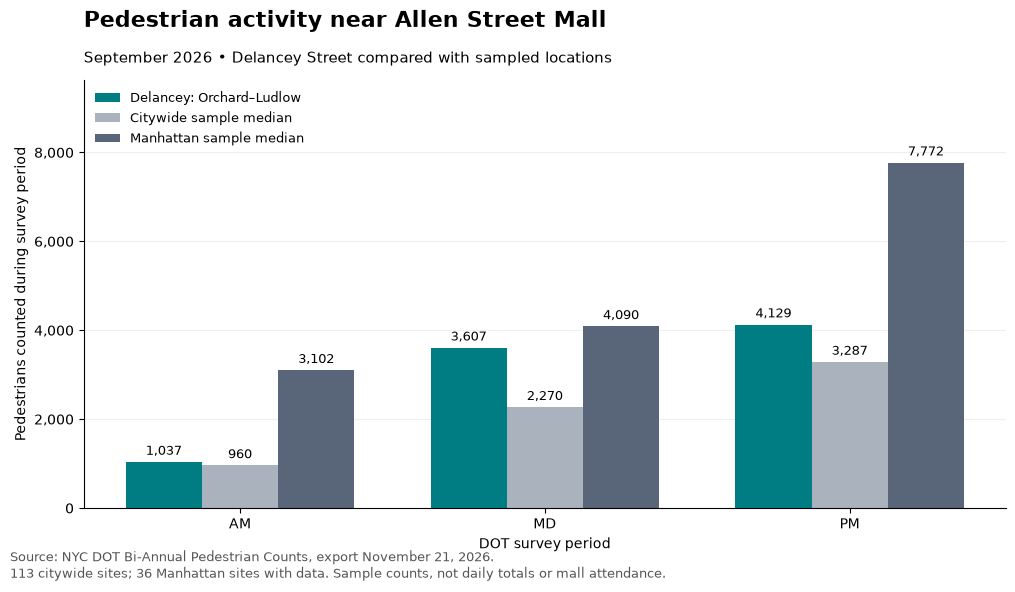

In [14]:
import matplotlib.pyplot as plt
import numpy as np

periods = ["AM", "MD", "PM"]
city = comparison.loc[comparison["comparison"].eq("All sampled sites")].set_index("period").reindex(periods)
manhattan = comparison.loc[comparison["comparison"].eq("Manhattan sampled sites")].set_index("period").reindex(periods)
x = np.arange(len(periods))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
for offset, values, label, color in [
    (-width, city["Delancey count"], "Delancey: Orchard–Ludlow", "#007C83"),
    (0, city["sample median"], "Citywide sample median", "#AAB2BD"),
    (width, manhattan["sample median"], "Manhattan sample median", "#596579"),
]:
    bars = ax.bar(x + offset, values, width, label=label, color=color)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values], padding=3, fontsize=9)

ax.set_title("Pedestrian activity near Allen Street Mall", loc="left", fontsize=16, weight="bold", pad=38)
ax.text(0, 1.04, "September 2026 • Delancey Street compared with sampled locations",
        transform=ax.transAxes, fontsize=11)
ax.set_xticks(x, periods)
ax.set_xlabel("DOT survey period")
ax.set_ylabel("Pedestrians counted during survey period")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.set_ylim(0, manhattan["sample median"].max() * 1.24)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.text(0, -0.04,
         "Source: NYC DOT Bi-Annual Pedestrian Counts, export November 21, 2026.\n"
         "113 citywide sites; 36 Manhattan sites with data. Sample counts, not daily totals or mall attendance.",
         fontsize=9, color="#555555")
plt.show()


# Summary

The number of pedestrians around Allen Street Mall was higher than the city-wide median for all pedestrian surveys done in September 2026, specifically in the mid-day and PM hours. Delancey Street had 3,607 pedestrians in the mid-day hour and 4,129 pedestrians in the PM hour, 59% and 26% above their city-wide medians, but lower than the median for the borough of Manhattan.